# C2 – Stabilität des 2D-FTCS-Verfahrens

Wir vergleichen drei Werte der Fourier-Zahl $r$ auf einem $50 \times 50$-Gitter über 200 Zeitschritte. Die obere Zeile bleibt auf 100, einschließlich der beiden Ecken. Die übrigen Randzellen und das Innere beginnen bei 0. Alle Randwerte bleiben fest.

Führe die Zellen von oben nach unten aus. Die letzte Codezelle speichert `stabilitaet.png` im Arbeitsverzeichnis des Notebooks.

## Ein Zeitschritt

Für jede innere Zelle gilt

$$T_{\mathrm{neu}} = T + r\,(T_{\mathrm{oben}} + T_{\mathrm{unten}} + T_{\mathrm{links}} + T_{\mathrm{rechts}} - 4T).$$

`temperatur` enthält den alten Zustand. Die NumPy-Ausschnitte wählen für alle inneren Zellen gleichzeitig die vier Nachbarn aus diesem Zustand aus. Die neuen Werte landen in `naechste_temperatur`. Erst danach wird die Kopie zum aktuellen Gitter. Nach jedem Schritt messen wir den größten Betrag im gesamten Gitter. So werden auch große negative Werte erfasst.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def simuliere(r, gittergroesse=50, anzahl_schritte=200):
    temperatur = np.zeros((gittergroesse, gittergroesse))
    temperatur[0, :] = 100.0
    maxima = np.empty(anzahl_schritte)

    for schritt in range(anzahl_schritte):
        # Nur das Innere der Kopie wird überschrieben.
        naechste_temperatur = temperatur.copy()
        innen = temperatur[1:-1, 1:-1]
        oben = temperatur[:-2, 1:-1]
        unten = temperatur[2:, 1:-1]
        links = temperatur[1:-1, :-2]
        rechts = temperatur[1:-1, 2:]

        naechste_temperatur[1:-1, 1:-1] = innen + r * (
            oben + unten + links + rechts - 4 * innen
        )
        temperatur = naechste_temperatur
        maxima[schritt] = np.abs(temperatur).max()

    return maxima

## Drei Werte im Vergleich

Für $0 \le r \le 0{,}25$ ist der neue Wert ein gewichteter Mittelwert. Die vier Nachbarn haben jeweils das Gewicht $r$, die Zelle selbst das Gewicht $1-4r$. Damit bleiben die Temperaturen zwischen 0 und 100. Bei $r=0{,}25$ zählt nur der Mittelwert der vier Nachbarn. Bei $r=0{,}3$ können Störungen anwachsen.

In [2]:
r_werte = (0.2, 0.25, 0.3)
anzahl_schritte = 200
maxima = {r: simuliere(r, anzahl_schritte=anzahl_schritte) for r in r_werte}

for r in r_werte:
    print(
        f"r = {str(r).replace('.', ',')} | "
        f"nach Schritt {anzahl_schritte}: {maxima[r][-1]:.3g}"
    )

assert all(np.all(maxima[r] == 100.0) for r in (0.2, 0.25))
assert np.isfinite(maxima[0.3]).all() and maxima[0.3][-1] > 1e20

r = 0,2 | nach Schritt 200: 100
r = 0,25 | nach Schritt 200: 100
r = 0,3 | nach Schritt 200: 1.67e+25


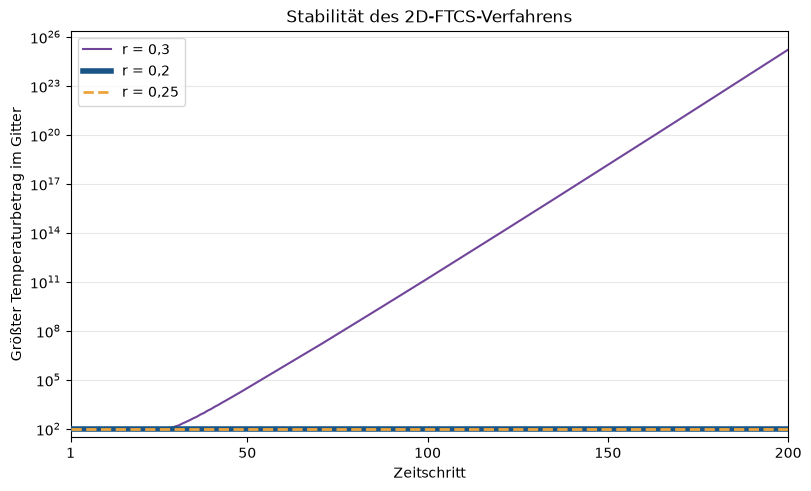

In [3]:
schritte = np.arange(1, anzahl_schritte + 1)
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
ax.semilogy(schritte, maxima[0.3], color="#70459A", label="r = 0,3", zorder=2)
# Beide stabilen Kurven liegen exakt übereinander.
ax.semilogy(schritte, maxima[0.2], color="#185486", linewidth=4, label="r = 0,2", zorder=3)
ax.semilogy(
    schritte, maxima[0.25], color="#ECA43B", linewidth=2,
    linestyle="--", label="r = 0,25", zorder=4,
)
ax.set(
    title="Stabilität des 2D-FTCS-Verfahrens",
    xlabel="Zeitschritt",
    ylabel="Größter Temperaturbetrag im Gitter",
    xlim=(1, anzahl_schritte),
    ylim=(30, None),
)
ax.set_xticks([1, 50, 100, 150, 200])
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper left")
fig.savefig("stabilitaet.png", dpi=150)
plt.show()